# Week 6 · 04 Convolution: the layer for images

A convolutional layer slides one small grid of weights (a **kernel**) over the image and, at every position, multiplies and adds. This notebook does it slowly: why images need it, one convolution by hand on a 4×4 image, the output-size formula, padding and stride, colour channels and how many parameters a layer has, pooling, and how far each pixel "sees". These are exactly the hand calculations the exam asks for. Two days: §M–3, then §4–7. Reading: UDL Ch. 10; d2l.ai Ch. 7.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **kernel (filter)**: a small grid of weights, e.g. 3×3, that is slid over the image. Each kernel detects one pattern.
- **feature map**: the output of one kernel: a grid saying how strongly the pattern appears at each position.
- **channel**: one grid of numbers making up an image or a feature map. A colour image has 3 channels (red, green, blue); a layer with 16 kernels outputs 16 channels.
- **padding**: a border of zeros added around the image before sliding the kernel.
- **stride**: how many pixels the kernel moves between positions (1 = every position, 2 = every other).
- **pooling**: shrinking a feature map by summarizing each small window, e.g. by its maximum.
- **receptive field**: the patch of the original image that one output pixel depends on.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from figures import *
import checks; checks.load(globals(), "04")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** What a convolutional layer does. One 3×3 kernel (left column $+1$, right column $-1$) slid over an MNIST image lights up wherever there's a vertical edge; the same kernel turned on its side finds horizontal edges. A CNN learns many such kernels.

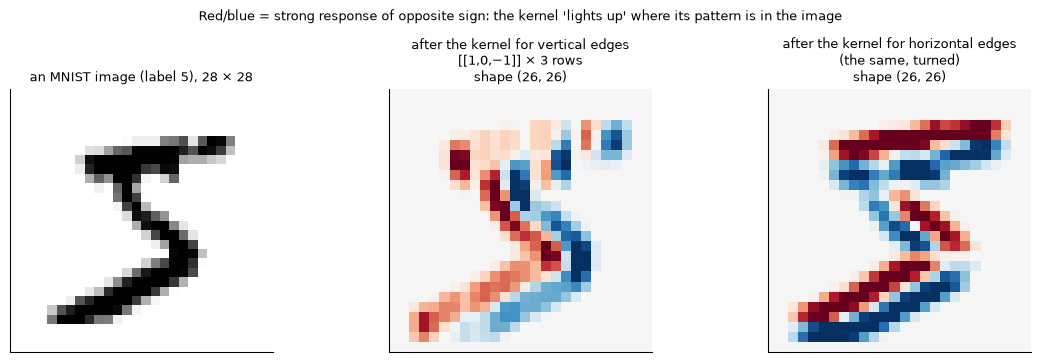

In [4]:
fig_edge_maps()

| Section | What | Why it's here |
|---|---|---|
| 0 | recap, and booklet 9.4's E-step from memory | spaced practice of an ML chapter |
| E | a finished convolutional layer and one output pixel | start from the end: what the layer stores and computes |
| 1 | why images need a different layer | the two problems of using a dense layer on pixels |
| 2 | a convolution by hand | 4×4 image, 3×3 kernel, every number |
| 3 | output size, padding, stride | the formula every exam asks for, with its proof |
| 4 | channels and parameter counts | colour images, many kernels, and counting weights |
| 5 | pooling | shrinking feature maps |
| 6 | receptive field | how much of the image a deep pixel sees |
| 7 | In Python | the block and exercises 2–5 |

## 0. Recap first · 10 min, closed book

**Quick check:** A dense layer from 784 inputs to 128 units: how many parameters?

<details><summary>Answer</summary>

$784 \cdot 128 + 128 = 100{,}480$. [Week 5 · 02 §8 ↗](../week5/02_neural_networks.ipynb)

</details>

**Quick check:** `x[i:i+3, j:j+3]` for a 2-D array `x` is ...?

<details><summary>Answer</summary>

The 3×3 block whose top-left corner is at row `i`, column `j` (rows `i`, `i+1`, `i+2`; same for the columns). [Week 1 · 02 ↗](../week1/02_numpy_lesson.ipynb)

</details>

**Quick check:** `A * B` vs `A @ B` for two 3×3 arrays?

<details><summary>Answer</summary>

`*` multiplies entry by entry (9 products); `@` is the matrix product. A convolution uses `*`, then a sum.

</details>

**Quick check:** `np.sum(A * B)` for two arrays of the same shape is what kind of product?

<details><summary>Answer</summary>

A dot product: multiply matching entries, add them all up. That's one output pixel of a convolution.

</details>

**Quick check:** In a GMM, what does the E-step compute?

<details><summary>Answer</summary>

The responsibilities $\gamma_{ik} = \frac{\pi_k\, \mathcal{N}(x_i \mid \mu_k, \Sigma_k)}{\sum_j \pi_j\, \mathcal{N}(x_i \mid \mu_j, \Sigma_j)}$: how much of point $i$ each component explains (a soft assignment, not a hard one). [Week 4 · 04 §3 ↗](../week4/04_hierarchical_dbscan_gmm.ipynb)

</details>

**Exercise 1 · Booklet 9.4: the GMM E-step.** Return the responsibilities, **shape `(n, K)`**: column $k$ is $\pi_k\, \mathcal{N}(x_i \mid \mu_k, \Sigma_k)$, then each row divided by its sum. `X` `(n, d)`, `pi` `(K,)`, `mu` `(K, d)`, `Sigma` `(K, d, d)`. As in the booklet, `multivariate_normal(mu[k], Sigma[k]).pdf(X)` (from `scipy.stats`) gives the density of every row of `X`.

**Example**: what goes in, and what should come out:
```python
X = np.array([[0.0], [3.0]]); mu = np.array([[0.0], [3.0]]); Sigma = np.array([[[1.0]], [[1.0]]])
gmm_e_step(X, np.array([0.5, 0.5]), mu, Sigma)
# → [[0.989 0.011]
#    [0.011 0.989]]    each point belongs mostly to the bump it sits on
```

In [5]:
from scipy.stats import multivariate_normal

X = np.array([[0.0], [3.0]]); mu = np.array([[0.0], [3.0]]); Sigma = np.array([[[1.0]], [[1.0]]])
for k in range(len(X)):
    print(multivariate_normal(mu[k],Sigma[k]).pdf(X))

[0.39894228 0.00443185]
[0.00443185 0.39894228]


In [6]:
from scipy.stats import multivariate_normal

def gmm_e_step(X, pi, mu, Sigma):                     
    K = len(pi)
    dens = np.column_stack([pi[k] * multivariate_normal(mu[k], Sigma[k]).pdf(X) for k in range(K)])  
    return dens / dens.sum(axis=1, keepdims=True)     

In [7]:
check(1)

Exercise 1: PASS


## E. Start from the end: a finished convolutional layer

A convolutional layer with one kernel stores very little: a $3 \times 3$ grid of weights and one bias. Here the weights are set by hand to the vertical-edge kernel (trained layers learn their own, `05` §E):

$$
K = \begin{pmatrix} 1 & 0 & -1 \\ 1 & 0 & -1 \\ 1 & 0 & -1 \end{pmatrix} \qquad \text{(left column minus right column)}
$$

In [ ]:
img, label = mnist_image(0)                             # from figures.py: a 28 x 28 float array in [0, 1], and its label
K = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1.0]])
conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, bias=False) #bias=False keeps the output a pure weighted sum.
with torch.no_grad():
    conv.weight.copy_(torch.tensor(K, dtype=torch.float32)[None, None])   # weight shape (out, in, 3, 3) = (1, 1, 3, 3)
out = conv(torch.tensor(img)[None, None])[0, 0].detach().numpy()          # input (N, C, H, W) = (1, 1, 28, 28)
print(label, conv.weight.shape, out.shape)          # → 5 torch.Size([1, 1, 3, 3]) (26, 26)

5 torch.Size([1, 1, 3, 3]) (26, 26)


**One output pixel by hand.** The strongest response is at row 9, column 12. The 3×3 window of the image there, rounded, is

$$
\begin{pmatrix} 0.99 & 0.80 & 0.04 \\ 0.99 & 0.35 & 0.00 \\ 0.99 & 0.75 & 0.01 \end{pmatrix} \;\to\; (0.99 + 0.99 + 0.99) - (0.04 + 0.00 + 0.01) = 2.93
$$

Bright on the left, dark on the right: a vertical edge (the left side of the 5's upright stroke), so the kernel's "left minus right" is large.

In [9]:
win = img[9:12, 12:15]                     # the window whose top-left corner is (9, 12)
print(round(float(np.sum(win * K)), 3), round(float(out[9, 12]), 3))    # → 2.925 2.925

2.925 2.925


**The rest of this notebook answers:** why slide a kernel at all (§1), how exactly each number is computed (§2), why the output is 26×26 and not 28×28 (§3), what changes for colour images and many kernels (§4), and what the layers after it do (§5–6).

## 1. Why images need a different layer

**The problem.** A dense layer (Week 5) connects every input to every unit. For images that has two flaws.

- **Too many weights.** A 28×28 image has 784 pixels; 128 units already need 100,352 weights. A 224×224 colour photo has 150,528 inputs: one layer of 1000 units would need 150 million weights.
- **It ignores where things are.** To a dense layer, pixel 300 and pixel 301 are unrelated inputs. A digit moved two pixels to the right hits completely different weights, so the network must learn "a 5" separately at every position.

**The idea.** Patterns in images are **local** (an edge is a few neighbouring pixels) and can appear **anywhere**. So use a small detector that looks at a few neighbouring pixels at a time, and slide the **same** detector over every position. A 3×3 kernel has 9 weights no matter how big the image is, and it finds its pattern wherever it is.

**In one sentence:** a convolutional layer uses one small set of weights, slid across the whole image, because image patterns are local and can be anywhere.

## 2. A convolution by hand

**The formula, piece by piece.** For an image $x$ and a $k \times k$ kernel $K$, the output pixel at row $i$, column $j$ is

$$
y_{ij} = \sum_{a=0}^{k-1}\sum_{b=0}^{k-1} x_{i+a,\, j+b}\; K_{ab} \;+\; \text{bias}
$$

- Put the kernel's top-left corner on image pixel $(i, j)$; it then covers rows $i \dots i+k-1$ and columns $j \dots j+k-1$.
- Multiply each covered pixel by the kernel weight on top of it ($x_{i+a, j+b} K_{ab}$).
- Add up all $k^2$ products, plus the bias. That's one output number.
- Move one pixel right and repeat; at the end of a row, move one down. In NumPy: `np.sum(x[i:i+k, j:j+k] * K)`.

🖼 **Picture.** A 4×4 image and the 3×3 "left minus right" kernel. The kernel fits in 2 positions across and 2 down, so the output is 2×2.

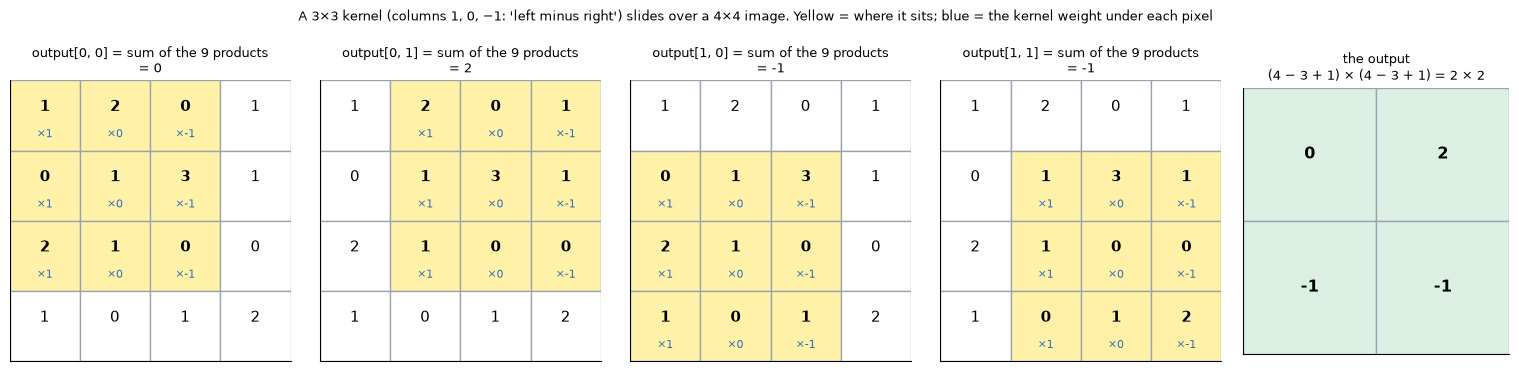

In [10]:
fig_conv_slide()

**Every number, by hand.** The kernel's columns are $(1, 0, -1)$, so each output is (sum of the window's left column) − (sum of its right column):

| Output | Window (rows, columns) | left column sum | right column sum | output |
|---|---|---|---|---|
| $y_{00}$ | rows 0–2, cols 0–2 | 1 + 0 + 2 = 3 | 0 + 3 + 0 = 3 | 0 |
| $y_{01}$ | rows 0–2, cols 1–3 | 2 + 1 + 1 = 4 | 1 + 1 + 0 = 2 | 2 |
| $y_{10}$ | rows 1–3, cols 0–2 | 0 + 2 + 1 = 3 | 3 + 0 + 1 = 4 | −1 |
| $y_{11}$ | rows 1–3, cols 1–3 | 1 + 1 + 0 = 2 | 1 + 0 + 2 = 3 | −1 |

In [28]:
x = np.array([[1, 2, 0, 1], 
              [0, 1, 3, 1], 
              [2, 1, 0, 0], 
              [1, 0, 1, 2.0]])     # (4, 4)
out = F.conv2d(torch.tensor(x)[None, None], torch.tensor(K)[None, None])      # F.conv2d wants (N, C, H, W) and (out, in, k, k)
print(out[0, 0])
print(out.shape)
# → tensor([[ 0.,  2.],
#           [-1., -1.]], dtype=torch.float64)

tensor([[ 0.,  2.],
        [-1., -1.]], dtype=torch.float64)
torch.Size([1, 1, 2, 2])


### What the code does

- **`torch.tensor(x)[None, None]`**: `[None, None]` adds two extra dimensions of size 1 at the front, so the shape goes from $(4, 4)$ to $(1, 1, 4, 4)$. PyTorch requires image input as **(batch size, channels, height, width)**. Here that's 1 image, 1 channel (grayscale), 4 tall, 4 wide. The numbers stay the same; only the shape changes.

- **`torch.tensor(K)[None, None]`** does the same to the $3 \times 3$ kernel, so $(3, 3)$ becomes $(1, 1, 3, 3)$. PyTorch wants the kernel as **(number of output channels, number of input channels, height, width)**: 1 output, 1 input, $3 \times 3$.

- **`F.conv2d(input, kernel)`** slides the kernel over the input, multiplies and adds at each position, and returns the result. `F` is `torch.nn.functional`, a set of plain functions. Unlike `nn.Conv2d`, it doesn't store any weights, so you pass the kernel in directly. It also adds no bias.

- **`out[0, 0]`** means "first image, first channel." It strips the two extra dimensions so you see only the $2 \times 2$ grid.

**Remark: "convolution" without the flip.** In mathematics a convolution flips the kernel first. Deep-learning libraries don't (strictly, they compute a cross-correlation), but everyone calls it convolution. On the exam, slide the kernel as it is, unless the question says to flip it.

**In one sentence:** each output pixel is the sum of the products between the kernel and the image patch under it, and sliding the kernel gives the whole output.

## 3. Output size, padding and stride

**The problem.** In §2 a 4×4 image became 2×2; in §E a 28×28 image became 26×26. Sizes shrink with every layer, and the pixels on the border are covered less often than those in the middle. And sometimes we **want** the output smaller, to save computation.

**The two knobs.** **Padding** $p$: add $p$ rings of zeros around the image first, so the kernel can sit on the border pixels and the size shrinks less (or not at all). **Stride** $s$: move the kernel $s$ pixels at a time instead of 1, so the output is about $s$ times smaller in each direction.

🖼 **Picture.** A 5×5 image (blue) and a 3×3 kernel. Padding 1 adds the grey zeros. Stride 2 makes the kernel jump two pixels between positions (orange → purple).

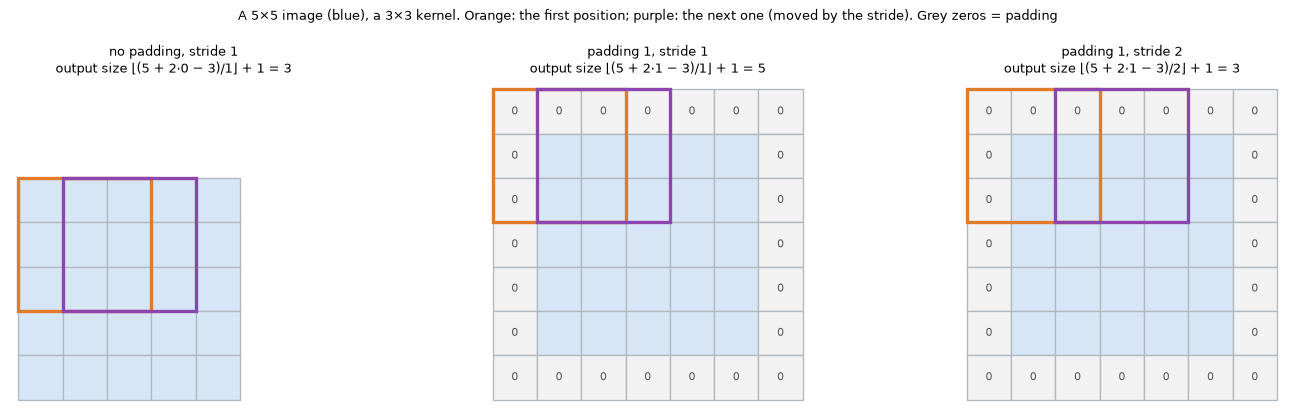

In [12]:
fig_padding_stride()

**Proposition.** For an $n \times n$ input, a $k \times k$ kernel, padding $p$ and stride $s$, the output is $m \times m$ with

$$
m = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1
$$

**What it says, in words.** After padding, the image is $n + 2p$ wide. The kernel's left edge can start at position 0, $s$, $2s$, ..., as long as the kernel still fits, i.e. as long as the start is at most $n + 2p - k$. The output size is the number of such starting positions.

**Small examples.** $n = 28$, $k = 3$: no padding gives $\frac{25}{1} + 1 = 26$ (§E). Padding 1 gives $\frac{27}{1} + 1 = 28$, the same size (called "same" padding: $p = (k - 1)/2$ for odd $k$). Padding 1 and stride 2 gives $\lfloor \frac{27}{2} \rfloor + 1 = 13 + 1 = 14$.

**The proof in plain words.** The allowed starting positions are $0, s, 2s, \dots, ts$, where $ts$ is the largest multiple of $s$ that is $\le n + 2p - k$. So $t = \lfloor (n + 2p - k) / s \rfloor$, and counting $0$ through $t$ gives $t + 1$ positions:

$$
\#\{\, t' \in \{0, 1, 2, \dots\} : t' s \le n + 2p - k \,\} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1. \qquad \blacksquare
$$

| $n$ | $k$ | $p$ | $s$ | $(n + 2p - k)/s$ | output $m$ |
|---|---|---|---|---|---|
| 28 | 3 | 0 | 1 | 25 | 26 |
| 28 | 3 | 1 | 1 | 27 | 28 (same) |
| 28 | 3 | 1 | 2 | 13.5 → 13 | 14 |
| 32 | 5 | 2 | 1 | 29 | 32 (same) |
| 7 | 3 | 0 | 2 | 2 | 3 |

**Remark: the floor.** When the stride doesn't divide evenly (13.5 above), the last partial position is dropped: the kernel never hangs off the edge. In PyTorch these are just arguments: `nn.Conv2d(1, 8, kernel_size=3, padding=1, stride=2)`.

**In one sentence:** the output size is $\lfloor (n + 2p - k)/s \rfloor + 1$, the number of positions where the kernel fits after padding, stepping by the stride.

## 4. Channels and parameter counts

**The problem.** A colour image isn't one grid but three: red, green and blue (3 **channels**). And one kernel finds one pattern; a useful layer needs many.

### Colour images as stacked channels

A $20 \times 20$ colour image is three $20 \times 20$ grids stacked on top of each other:

```
  ┌─────────┐
  │  Blue   │  20 × 20
 ┌─────────┐│
 │  Green  ││  20 × 20
┌─────────┐│┘
│   Red   │┘   20 × 20
└─────────┘
```

- **Red layer:** how much red each pixel has.
- **Green layer:** how much green each pixel has.
- **Blue layer:** how much blue each pixel has.

One pixel at position $(i, j)$ is the three numbers you hit if you poke straight down through the stack at that spot. For example, $(R, G, B) = (1.0, 0.0, 0.0)$ is pure red, and $(1, 1, 1)$ is white.

**Shape in code:**

- **PyTorch:** puts the channels first, so the image is $(3, 20, 20)$. With the batch dimension it's $(1, 3, 20, 20)$.
- **numpy, PIL and matplotlib:** usually put the channels last, so the same image is $(20, 20, 3)$.

**The idea.** 

(1) Make the kernel as **deep** as the input: for 3 input channels, a $3 \times 3 \times 3$ block of weights. At each position it multiplies all 27 covered values and adds them: one number, so one kernel still gives one feature map. 

(2) Use $C_{\text{out}}$ such kernels; their maps, stacked, are the output's $C_{\text{out}}$ channels.

Each kernel slides over the input and produces one output grid, called a **feature map** (e.g. "where are the vertical edges?"). Using $C_{\text{out}}$ different kernels gives $C_{\text{out}}$ feature maps, and stacking them, like the R, G, B layers of a colour image, gives an output with $C_{\text{out}}$ channels. For example, 3 kernels on a $28 \times 28$ image give an output of shape $(3, 26, 26)$.

🖼 **Picture.** `nn.Conv2d(3, 16, 3)` on a 32×32 colour image: each of the 16 kernels is $3 \times 3 \times 3$ and produces one 30×30 map, so the output is 16 × 30 × 30.

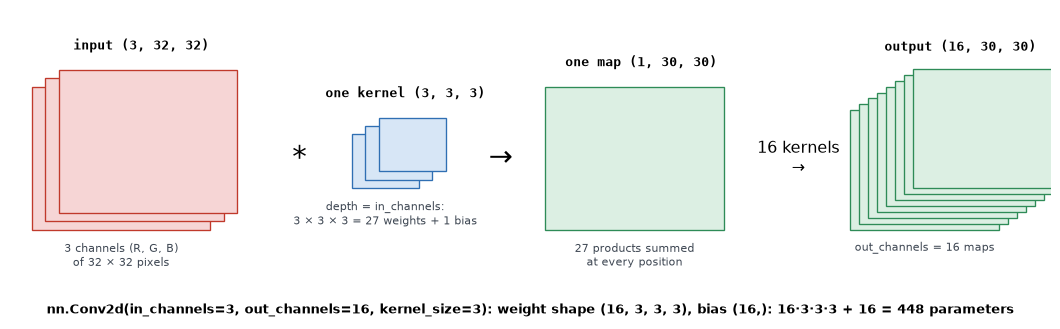

In [13]:
fig_channels()

**The formula, piece by piece.** Output channel $o$ at position $(i, j)$:

$$
y_{o,i,j} = \sum_{c=1}^{C_{\text{in}}}\sum_{a=0}^{k-1}\sum_{b=0}^{k-1} x_{c,\, i+a,\, j+b}\; W_{o,c,a,b} \;+\; \text{bias}_o
$$

Same as §2, with one more sum: over the input channels $c$. The weight has 4 indices, so PyTorch stores it as shape **`(C_out, C_in, k, k)`** (output channel first, as `nn.Linear` puts the output first).

**Counting the parameters.** Each of the $C_{\text{out}}$ kernels has $C_{\text{in}} \cdot k \cdot k$ weights plus 1 bias:

$$
\#\text{params} = C_{\text{out}} \cdot C_{\text{in}} \cdot k^2 + C_{\text{out}}
$$

| Layer | Calculation | Parameters |
|---|---|---|
| `Conv2d(1, 8, 3)` | 8 · 1 · 9 + 8 | 80 |
| `Conv2d(3, 16, 3)` | 16 · 3 · 9 + 16 | 448 |
| `Conv2d(16, 32, 3)` | 32 · 16 · 9 + 32 | 4,640 |
| `Conv2d(3, 64, 7)` | 64 · 3 · 49 + 64 | 9,472 |

**Compare with a dense layer doing the same job.** From $3 \times 32 \times 32 = 3072$ inputs to $16 \times 30 \times 30 = 14{,}400$ outputs, a dense layer would need $3072 \times 14{,}400 = 44{,}236{,}800$ weights. The convolution needs 448: it uses the same few weights at every position (weight sharing). Note the count **doesn't depend on the image size** at all.

In [29]:
for c_in, c_out, k in [(1, 8, 3), (3, 16, 3), (16, 32, 3)]:
    layer = nn.Conv2d(c_in, c_out, k)
    print(tuple(layer.weight.shape), sum(p.numel() for p in layer.parameters()))
# → (8, 1, 3, 3) 80
#   (16, 3, 3, 3) 448
#   (32, 16, 3, 3) 4640

(8, 1, 3, 3) 80
(16, 3, 3, 3) 448
(32, 16, 3, 3) 4640


**In one sentence:** a convolution's kernel is as deep as the input's channels, each kernel makes one output channel, and the layer has $C_{\text{out}} C_{\text{in}} k^2 + C_{\text{out}}$ parameters whatever the image size.

## 5. Pooling

**The problem.** Feature maps are as large as the image, and a deep network has many of them. We'd like to shrink them as we go, and to care less about the exact pixel where a pattern appeared.

**The idea.** Cut each map into small windows (usually 2×2) and keep only one number per window: the **maximum** (max pooling) or the average. A 2×2 pool with stride 2 halves the height and the width.

### Why pooling?

**Problem 1: too many numbers.** A conv layer with 32 kernels on a $28 \times 28$ image gives $32 \times 26 \times 26 = 21{,}632$ numbers, and deeper layers add more channels.
**Fix:** $2 \times 2$ pooling keeps 1 value out of every 4, so $26 \times 26 \to 13 \times 13$ ($5{,}408$ numbers in total).

**Problem 2: exact position doesn't matter.** A "7" shifted one pixel is still a 7.
**Fix:** max pooling keeps only the largest value per window: *was the pattern here?*, not *exactly where?*

```
0 9 | 0 0           9 0 | 0 0
0 0 | 0 1           0 0 | 0 1
----+----   ->      ----+----   (9 shifted one pixel)
0 0 | 0 0           0 0 | 0 0
2 0 | 0 0           2 0 | 0 0

max pool: 9 1       max pool: 9 1
          2 0                 2 0   <- same output
```

**Bonus:** on a smaller map, the next layer's $3 \times 3$ kernel covers a larger area of the original image, so deeper layers can detect bigger patterns.

🖼 **Picture.** Max pooling 2×2: each coloured window keeps its largest value. 4×4 becomes 2×2.

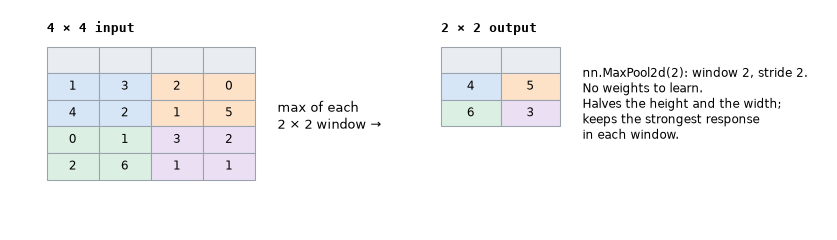

In [15]:
fig_maxpool()

**Facts to remember.** 

(1) Pooling has **no parameters**: nothing to learn. --> pooling is a fixed rule.

(2) It acts on each channel separately, so the number of channels doesn't change: (8, 28, 28) becomes (8, 14, 14). 

(3) Its output size follows the same formula as §3, with $k = s = 2$, $p = 0$: $\lfloor (n - 2)/2 \rfloor + 1 = n/2$ for even $n$. 

(4) If the pattern moves by one pixel inside a window, the maximum stays the same: a little robustness to small shifts.

In [30]:
xp = np.array([[1, 3, 2, 0], 
               [4, 2, 1, 5], 
               [0, 1, 3, 2], 
               [2, 6, 1, 1.0]])
print(F.max_pool2d(torch.tensor(xp)[None, None], kernel_size=2)[0, 0])
# → tensor([[4., 5.],
#           [6., 3.]], dtype=torch.float64)

tensor([[4., 5.],
        [6., 3.]], dtype=torch.float64)


**In one sentence:** max pooling keeps the largest value in each small window, halving the map's size with no weights to learn.

## 6. Receptive field: how much does one pixel see?

**The problem.** A 3×3 kernel only sees 9 pixels. How can a network recognize a whole digit with such small windows?

**The idea.** Stack them. A pixel in the second layer is computed from a 3×3 patch of the first layer's map, and each of those 9 values came from its own 3×3 patch of the image; together they cover 5×5 image pixels. Every extra 3×3 layer (stride 1) adds one pixel on each side.

### Receptive field: why stacking small kernels works

**The problem.** A $3 \times 3$ kernel sees only 9 pixels. That's enough for a small edge, but not for a whole digit.

**The idea.** Stack conv layers. A layer-2 value sees a $3 \times 3$ patch of layer 1, and each of those values saw its own $3 \times 3$ patch of the image. The patches overlap and together cover $5 \times 5$ image pixels. Each extra layer adds one pixel on each side:

| Layers | Image area one value sees |
|---|---|
| 1 | $3 \times 3$ |
| 2 | $5 \times 5$ |
| 3 | $7 \times 7$ |
| $n$ | $(2n+1) \times (2n+1)$ |

**Result.** Early layers see small areas and detect edges. Deeper layers see more of the image and combine edges into strokes, loops, and whole shapes.

**Essentially the field of view gets bigger as the layers go deeper.**


🖼 **Picture.** The patch of the input that one output pixel depends on, after 1, 2 and 3 layers of 3×3 convolutions: 3×3, 5×5, 7×7.

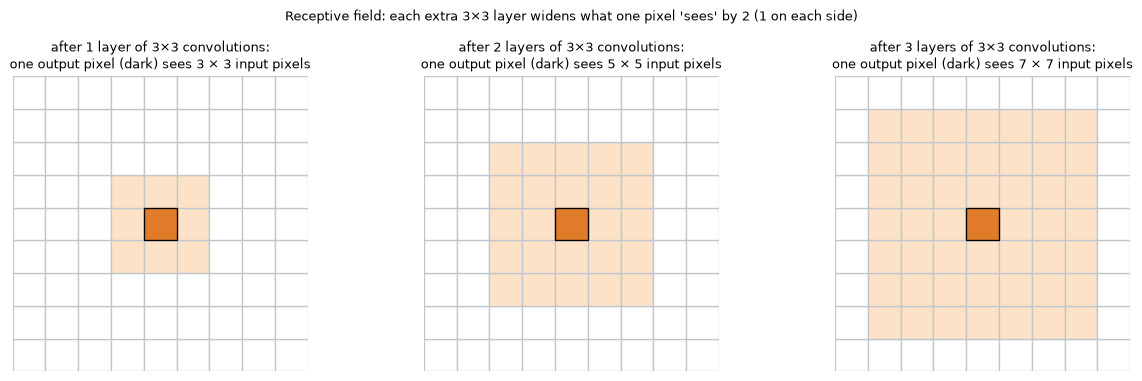

In [17]:
fig_receptive_field()

**The rule.** For $L$ stacked $k \times k$ convolutions with stride 1, the receptive field is $1 + L(k - 1)$ pixels wide: $1 + 2L$ for $k = 3$. Pooling makes it grow much faster: after a 2×2 pool, each step in the next layer is 2 input pixels, so the next 3×3 layer adds 4 instead of 2. That's how a few small layers end up seeing the whole digit.

**Remark: why stacks of 3×3.** Two 3×3 layers see 5×5, like one 5×5 kernel, but with $2 \times 9 = 18$ weights per channel pair instead of 25, and with a ReLU in between. That's the idea behind the VGG networks (`05` §5).

The remark compares two ways to give a layer a $5 \times 5$ view of the image, and says why the stacked $3 \times 3$ way is better.

- **Option A: one $5 \times 5$ kernel.** It sees a $5 \times 5$ area directly and has $5 \times 5 = 25$ weights.
- **Option B: two $3 \times 3$ layers stacked.** From the receptive field idea, the second layer also sees a $5 \times 5$ area of the image. Each layer has 9 weights, so $2 \times 9 = 18$ weights.

**In one sentence:** each stacked 3×3 layer widens what a pixel sees by 2, and pooling speeds that up, so deep layers see large parts of the image.

## 7. In Python: the block and its exercises

The code cells of §E and §2–5 together are this notebook's "In Python" block: a convolution by hand checked against `F.conv2d`, output sizes, parameter counts and pooling checked against PyTorch. The exercises are its hand-written parts, which are also the exam's hand calculations.

**Exercise 2 · Output size.** Return $\lfloor (n + 2p - k) / s \rfloor + 1$ (an `int`; `//` is integer division in Python). The check compares with the shapes PyTorch produces.

**Example**: what goes in, and what should come out:
```python
conv_out_size(28, 3)          # → 26
conv_out_size(28, 3, 1, 2)    # → 14
```

In [33]:
def conv_out_size(n, k, p=0, s=1):
    return (n+2*p-k)//s + 1

In [34]:
check(2)

Exercise 2: PASS


**Exercise 3 · A convolution by hand.** One channel, stride 1, no padding: `x` is `(h, w)`, `K` is `(a, b)`. Return the `(h - a + 1, w - b + 1)` output with `out[i, j] = np.sum(x[i:i+a, j:j+b] * K)`: two loops over the output positions. The check compares with `F.conv2d`.

**Example**: what goes in, and what should come out:
```python
conv2d_single(x, K)     # x and K from §2
# → [[ 0.  2.]
#    [-1. -1.]]
```

In [39]:
x = np.array([[1, 2, 0, 1], 
              [0, 1, 3, 1], 
              [2, 1, 0, 0], 
              [1, 0, 1, 2.0]])
K = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1.0]])
print(x.shape[1])

4


In [41]:
def conv2d_single(x, K):
    a, b = K.shape
    out = np.zeros((x.shape[0] - a + 1, x.shape[1] - b + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(x[i:i + a, j:j + b] * K)   
    return out

In [42]:
check(3)

Exercise 3: PASS


**Exercise 4 · Parameter count of a convolution.** Return $C_{\text{out}} \cdot C_{\text{in}} \cdot k^2 + C_{\text{out}}$ for `nn.Conv2d(c_in, c_out, k)`.

**Example**: what goes in, and what should come out:
```python
conv_params(3, 16, 3)     # → 448
```

In [43]:
def conv_params(c_in, c_out, k):
    return c_out * c_in * (k**2) + c_out

In [44]:
check(4)

Exercise 4: PASS


**Exercise 5 · Max pooling.** `x` is `(h, w)` with both divisible by `size`. Return the `(h // size, w // size)` array of the maximum of each `size × size` window (stride = size). Loops are fine; or the one-liner `x.reshape(h // size, size, w // size, size).max(axis=(1, 3))` (cut the rows into groups of `size`, the columns too, then take the max over each group).

**Example**: what goes in, and what should come out:
```python
maxpool2d(xp, 2)     # xp from §5
# → [[4. 5.]
#    [6. 3.]]
```

In [46]:
def maxpool2d(x, size=2):
    h,w = x.shape
    return x.reshape(h//size, size, w//size, size).max(axis=(1,3))

### How the reshape trick does max pooling

**Step 1: the 1D version.** `reshape` chops a row into pairs, and `.max` collapses each pair:

```python
row = np.array([1, 3, 2, 0])
row.reshape(2, 2)               # [[1, 3],
                                #  [2, 0]]
row.reshape(2, 2).max(axis=1)   # [3, 2]  ->  max(1,3), max(2,0)
```

**Step 2: 2D does the same in both directions.** `x.reshape(h//size, size, w//size, size)` chops the rows into pairs *and* the columns into pairs. Every pixel `x[r, c]` gets a new 4-part address `x4[I, a, J, b]`:

| Index | Formula | Meaning |
|---|---|---|
| $I$ | `r // 2` | which row of windows |
| $a$ | `r % 2` | row inside the window |
| $J$ | `c // 2` | which column of windows |
| $b$ | `c % 2` | column inside the window |

For example, `x[1, 0]` becomes `x4[0, 1, 0, 0]`: top-left window, second row, first column.

**Step 3: collapse each window.** Pixels in the same window share $I$ and $J$; only $a$ and $b$ differ. So `.max(axis=(1, 3))` takes the max over the positions inside each window, leaving one number per window:

```python
x = np.array([[1,3,2,0],[4,2,1,1],[0,1,5,2],[2,0,3,4]])
x4 = x.reshape(2, 2, 2, 2)
x4[0, :, 0, :]          # top-left window     -> [[1, 3], [4, 2]]
x4[1, :, 1, :]          # bottom-right window -> [[5, 2], [3, 4]]
x4.max(axis=(1, 3))     # [[4, 2],
                        #  [2, 5]]
```

**In short:** the 1D trick done twice. Chop the rows into pairs, chop the columns into pairs, then take the max inside each window.

In [47]:
check(5)

Exercise 5: PASS


**Recipe (the hand calculations).** Output size $\lfloor (n + 2p - k)/s \rfloor + 1$, separately for height and width; weight shape $(C_{\text{out}}, C_{\text{in}}, k, k)$; parameters $C_{\text{out}} C_{\text{in}} k^2 + C_{\text{out}}$; pooling keeps the channels and divides height and width by its size; one output pixel = sum of (window × kernel) + bias.

In [48]:
for n in range(1, 6):
    check(n)

Exercise 1: PASS
Exercise 2: PASS
Exercise 3: PASS
Exercise 4: PASS
Exercise 5: PASS


---
Solutions: `solutions/04_solutions.py`. Next: `05_cnn_in_pytorch.ipynb`, where these layers become a network.